# 22 · ML in Production — Shipping Models and Keeping Them Healthy

A model in a notebook creates no value. It creates value when it's **running in a system**, making decisions on fresh data, every day — and that's where most ML projects actually fail. Famously, the model code is a small box in a large diagram of data pipelines, serving infrastructure, monitoring and feedback.

This notebook takes the churn model from notebooks 08–09 through the production lifecycle, building small, runnable versions of each piece:

**What you'll learn**
1. Packaging a model with **versioning** and a minimal **model registry**
2. **Validating inputs** — per request (schemas) and per batch (data checks)
3. **Serving:** a real HTTP API with FastAPI, batch vs online, latency and batching
4. **Training–serving skew** — the silent killer, demonstrated
5. **Monitoring for drift:** PSI and KS tests — 🐍 pure Python → 🔢 NumPy → 📦 SciPy — and performance tracking
6. Safe rollout: **shadow mode, canary, A/B tests**, rollback
7. **Retraining** when the world changes (concept drift)
8. **Testing ML systems:** invariance, directional and minimum-performance tests
9. A production readiness checklist

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, time, hashlib, shutil, warnings
from pathlib import Path
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
warnings.filterwarnings("ignore", category=UserWarning)
rng = np.random.default_rng(0)

from churn_utils import load_raw, clean, add_features, CATEGORICAL, TARGET
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

raw = load_raw()
df = add_features(clean(raw))
X, y = df.drop(columns=TARGET), df[TARGET].to_numpy()
X_train, X_live, y_train, y_live = train_test_split(X, y, test_size=0.5, random_state=0, stratify=y)   # half = "future production traffic"
NUMERIC = [c for c in X.columns if c not in CATEGORICAL]

def build_pipeline(C=1.0):
    prep = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUMERIC),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(C=C, max_iter=2000))])

model_v1 = build_pipeline().fit(X_train, y_train)
print(f"model v1 trained on {len(X_train)} customers")

model v1 trained on 3000 customers


## 1. Packaging, versioning and a model registry

To answer "which model made this prediction, trained on what, with which code?" months later, every model needs an identity. A **model registry** stores each version with its **artifacts** (the serialized pipeline) and **metadata**: training data fingerprint, parameters, metrics, library versions, and a lifecycle **stage** (staging → production → archived). Tools: MLflow, Weights & Biases, SageMaker/Vertex registries. Here's the idea in 40 lines:

In [2]:
import joblib, sklearn, platform

class ModelRegistry:
    """A minimal file-based model registry: models/<name>/v<k>/{model.joblib, meta.json}."""
    def __init__(self, root="models/registry"):
        self.root = Path(root); self.root.mkdir(parents=True, exist_ok=True)
    def register(self, name, model, X_tr, y_tr, metrics, params=None):
        versions = sorted(int(p.name[1:]) for p in (self.root / name).glob("v*")) if (self.root / name).exists() else []
        v = (versions[-1] + 1) if versions else 1
        d = self.root / name / f"v{v}"; d.mkdir(parents=True)
        joblib.dump(model, d / "model.joblib")
        meta = {"name": name, "version": v, "stage": "staging", "registered_at": time.strftime("%Y-%m-%d %H:%M:%S"),
                "data_fingerprint": hashlib.sha256(pd.util.hash_pandas_object(X_tr, index=False).values.tobytes()).hexdigest()[:12],
                "n_train": len(X_tr), "features": list(X_tr.columns), "metrics": metrics, "params": params or {},
                "env": {"python": platform.python_version(), "sklearn": sklearn.__version__}}
        (d / "meta.json").write_text(json.dumps(meta, indent=2))
        return v
    def set_stage(self, name, version, stage):
        for p in (self.root / name).glob("v*"):                     # only one production model at a time
            m = json.loads((p / "meta.json").read_text())
            if stage == "production" and m["stage"] == "production": m["stage"] = "archived"
            if m["version"] == version: m["stage"] = stage
            (p / "meta.json").write_text(json.dumps(m, indent=2))
    def load(self, name, stage="production"):
        for p in sorted((self.root / name).glob("v*")):
            m = json.loads((p / "meta.json").read_text())
            if m["stage"] == stage: return joblib.load(p / "model.joblib"), m
        raise LookupError(f"no {stage} model for {name}")

shutil.rmtree("models/registry", ignore_errors=True)
registry = ModelRegistry()
auc_v1 = roc_auc_score(y_live[:500], model_v1.predict_proba(X_live[:500])[:, 1])
v = registry.register("churn", model_v1, X_train, y_train, {"holdout_auc": round(auc_v1, 4)}, {"C": 1.0})
registry.set_stage("churn", v, "production")
prod_model, prod_meta = registry.load("churn")
print(json.dumps({k: prod_meta[k] for k in ["name", "version", "stage", "data_fingerprint", "metrics", "env"]}, indent=2))

{
  "name": "churn",
  "version": 1,
  "stage": "production",
  "data_fingerprint": "687982265cd1",
  "metrics": {
    "holdout_auc": 0.8127
  },
  "env": {
    "python": "3.13.18",
    "sklearn": "1.9.1"
  }
}


## 2. Validating inputs

Production data is messier than training data — upstream teams rename columns, change units, ship nulls. Two layers of defence:

**Per request — a schema.** Reject malformed requests with a clear error instead of returning a confident nonsense prediction. `pydantic` declares types and constraints:

In [3]:
from pydantic import BaseModel, Field, ValidationError
from typing import Literal, Optional

class Customer(BaseModel):
    age: Optional[float] = Field(None, ge=18, le=100)
    region: str
    plan: Literal["basic", "standard", "premium"]
    contract: Literal["month-to-month", "one-year", "two-year"]
    payment_method: str
    has_partner: Literal["yes", "no"]
    monthly_charges: float = Field(gt=0, lt=1000)
    tenure_months: int = Field(ge=0, le=600)
    total_charges: Optional[float] = Field(None, ge=0)
    support_calls: int = Field(ge=0, le=100)
    avg_session_minutes: Optional[float] = Field(None, ge=0)
    satisfaction_score: Optional[float] = Field(None, ge=1, le=5)
    last_login_days_ago: int = Field(ge=0)

good = dict(age=34, region="north", plan="premium", contract="month-to-month", payment_method="electronic check", has_partner="no",
            monthly_charges=99.0, tenure_months=3, total_charges=290.0, support_calls=4, avg_session_minutes=12.0,
            satisfaction_score=None, last_login_days_ago=21)
print("valid request parsed:", Customer(**good).plan)
try:
    Customer(**{**good, "monthly_charges": -50, "contract": "lifetime"})
except ValidationError as e:
    print(f"rejected with {e.error_count()} errors:", [(err['loc'][0], err['msg']) for err in e.errors()])

valid request parsed: premium
rejected with 2 errors: [('contract', "Input should be 'month-to-month', 'one-year' or 'two-year'"), ('monthly_charges', 'Input should be greater than 0')]


**Per batch — data checks.** For batch jobs and monitoring, check the whole table before scoring: schema, missing rates, ranges, unseen categories, row counts. (Libraries: Great Expectations, Pandera, TFDV.)

In [4]:
# 🐍 A small batch validator: returns a list of human-readable problems
def validate_batch(batch, reference):
    problems = []
    missing_cols = set(reference.columns) - set(batch.columns)
    if missing_cols: problems.append(f"missing columns: {sorted(missing_cols)}")
    for c in reference.columns.intersection(batch.columns):
        ref_null, new_null = reference[c].isna().mean(), batch[c].isna().mean()
        if new_null > ref_null + 0.10: problems.append(f"{c}: missing rate jumped {ref_null:.0%} → {new_null:.0%}")
        if c in CATEGORICAL:
            unseen = set(batch[c].dropna()) - set(reference[c].dropna())
            if unseen: problems.append(f"{c}: unseen categories {sorted(unseen)}")
        elif pd.api.types.is_numeric_dtype(batch[c]):
            lo, hi = reference[c].quantile(0.001), reference[c].quantile(0.999)
            out = ((batch[c] < lo - (hi - lo)) | (batch[c] > hi + (hi - lo))).mean()
            if out > 0.01: problems.append(f"{c}: {out:.1%} of values far outside the training range")
    if len(batch) < 50: problems.append(f"only {len(batch)} rows — upstream job may have failed")
    return problems

bad_batch = X_live[:300].copy()
bad_batch["monthly_charges"] = bad_batch["monthly_charges"] * 100          # someone switched dollars → cents
bad_batch.loc[bad_batch.index[:120], "satisfaction_score"] = np.nan       # survey pipeline broke
bad_batch.loc[bad_batch.index[:10], "region"] = "central"                 # a new market launched
print("clean batch:", validate_batch(X_live[:300], X_train) or "OK")
print("bad batch:"); [print("  ⚠", p) for p in validate_batch(bad_batch, X_train)]

clean batch: OK
bad batch:
  ⚠ region: unseen categories ['central']
  ⚠ monthly_charges: 99.7% of values far outside the training range
  ⚠ satisfaction_score: missing rate jumped 13% → 47%


[None, None, None]

## 3. Serving

**Batch vs online:**
| | Batch scoring | Online (real-time) serving |
|---|---|---|
| When | nightly/hourly job scores everyone, writes results to a table | an API scores one request on demand |
| Latency need | minutes–hours | milliseconds |
| Good for | churn lists, reports, email campaigns | fraud checks at payment time, search ranking, recommendations |
| Complexity | low | higher: uptime, latency, scaling |

Churn is a natural **batch** use case — but let's build an **online API** too, since many systems need one. `FastAPI` turns a Python function into an HTTP endpoint with automatic validation (via the pydantic schema above). We test it in-process with `TestClient` — the same requests a real client would send over the network.

In [5]:
from fastapi import FastAPI, HTTPException
from fastapi.testclient import TestClient

app = FastAPI(title="Churn model API")
SERVING_MODEL, SERVING_META = registry.load("churn")
THRESHOLD = 0.25                                                          # from notebook 09's cost analysis

def to_features(customers):
    """Raw validated records → the exact feature frame used in training (SAME code path as training!)."""
    raw_df = pd.DataFrame([c.model_dump() for c in customers]).assign(customer_id="api", signup_date="2025-01-01",
                                                                      cancellation_reason=None, churned=0)
    return add_features(clean(raw_df)).drop(columns=TARGET)[SERVING_META["features"]]

@app.get("/health")
def health():
    return {"status": "ok", "model": SERVING_META["name"], "version": SERVING_META["version"]}

@app.post("/predict")
def predict(customer: Customer):
    p = float(SERVING_MODEL.predict_proba(to_features([customer]))[0, 1])
    return {"churn_probability": round(p, 4), "contact": p >= THRESHOLD, "model_version": SERVING_META["version"]}

@app.post("/predict_batch")
def predict_batch(customers: list[Customer]):
    if len(customers) > 1000: raise HTTPException(413, "max 1000 customers per request")
    p = SERVING_MODEL.predict_proba(to_features(customers))[:, 1]
    return {"churn_probability": [round(float(x), 4) for x in p], "model_version": SERVING_META["version"]}

client = TestClient(app)
print("GET /health →", client.get("/health").json())
print("POST /predict →", client.post("/predict", json=good).json())
r = client.post("/predict", json={**good, "plan": "platinum"})
print("POST /predict (invalid) →", r.status_code, r.json()["detail"][0]["msg"])

GET /health → {'status': 'ok', 'model': 'churn', 'version': 1}
POST /predict → {'churn_probability': 0.9625, 'contact': True, 'model_version': 1}


POST /predict (invalid) → 422 Input should be 'basic', 'standard' or 'premium'


In production you'd run this with `uvicorn app:app --workers 4` inside a Docker container behind a load balancer, with autoscaling, health checks, request logging and authentication.

### Latency and batching
Per-request overhead (parsing, Python calls, data-frame building) usually dwarfs the model's own compute for small models. **Batching** many predictions into one call amortises that overhead — servers often do *dynamic batching*: wait a few milliseconds to collect concurrent requests, then score them together.

In [6]:
payload = [{**good, "tenure_months": int(t)} for t in rng.integers(0, 48, 200)]
t0 = time.perf_counter()
for p_ in payload: client.post("/predict", json=p_)
t_single = time.perf_counter() - t0
t0 = time.perf_counter(); client.post("/predict_batch", json=payload); t_batch = time.perf_counter() - t0
print(f"200 predictions — one request each: {t_single * 1000:.0f} ms ({t_single / 200 * 1000:.1f} ms/prediction) | "
      f"one batched request: {t_batch * 1000:.0f} ms ({t_batch / 200 * 1000:.2f} ms/prediction)")

lat = []
for p_ in payload:
    t0 = time.perf_counter(); client.post("/predict", json=p_); lat.append((time.perf_counter() - t0) * 1000)
print(f"single-request latency: p50 {np.percentile(lat, 50):.1f} ms, p95 {np.percentile(lat, 95):.1f} ms, p99 {np.percentile(lat, 99):.1f} ms")
print("(report percentiles, not averages — the slowest 1% of requests is what users complain about)")

200 predictions — one request each: 2036 ms (10.2 ms/prediction) | one batched request: 13 ms (0.07 ms/prediction)


single-request latency: p50 9.5 ms, p95 12.6 ms, p99 15.5 ms
(report percentiles, not averages — the slowest 1% of requests is what users complain about)


## 4. Training–serving skew

The model sees features computed one way in training and **a slightly different way in production** — a different library version, a re-implementation in another language, a feature computed with today's data instead of the data available at prediction time. No error is raised. Predictions just quietly get worse.

Demonstration: the serving team re-implements the cleaning step but forgets to normalise the `region` text ("NORTH", "North " stay as-is) and fills missing `satisfaction_score` with 0 instead of leaving it missing for the pipeline's imputer.

In [7]:
def clean_reimplemented(raw_df):
    out = raw_df.drop_duplicates().copy()
    out["total_charges"] = pd.to_numeric(out["total_charges"], errors="coerce").fillna(0)
    out["satisfaction_score"] = out["satisfaction_score"].fillna(0)              # ✗ training left it missing → imputed median
    return out.drop(columns=["customer_id", "cancellation_reason", "signup_date"])   # ✗ forgot region normalisation, age/charge fixes

raw_live = raw.loc[raw.index.isin(X_live.index)]
X_correct = add_features(clean(raw_live)).drop(columns=TARGET)
X_skewed = add_features(clean_reimplemented(raw_live)).drop(columns=TARGET)[X_correct.columns]
y_raw_live = add_features(clean(raw_live))[TARGET].to_numpy()
p_ok, p_bad = model_v1.predict_proba(X_correct)[:, 1], model_v1.predict_proba(X_skewed)[:, 1]
print(f"AUC with the shared cleaning code: {roc_auc_score(y_raw_live, p_ok):.3f} | with the re-implementation: {roc_auc_score(y_raw_live, p_bad):.3f}")
print(f"customers whose contact decision flips: {np.mean((p_ok >= THRESHOLD) != (p_bad >= THRESHOLD)):.1%}  — and nothing crashed")

AUC with the shared cleaning code: 0.817 | with the re-implementation: 0.807
customers whose contact decision flips: 3.5%  — and nothing crashed


**Prevention:** use **one code path** for features in training and serving (here: `churn_utils.clean` + the saved pipeline), or a **feature store** that serves the same feature values to both; log the features actually used at serving time and compare their distributions with training (next section); and add **parity tests** that run both code paths on the same records.

## 5. Monitoring for drift

After launch, the world moves: prices change, new markets open, competitor offers appear. Kinds of change to watch:
- **Data (covariate) drift:** the input distribution P(X) shifts.
- **Prediction drift:** the distribution of the model's outputs shifts.
- **Concept drift:** the relationship P(y | X) changes — the same customer profile now behaves differently. Only visible once labels arrive (for churn: weeks later).

### Population Stability Index (PSI)
Bin the training (reference) values into deciles; compare the share of production values in each bin:
$$ \text{PSI} = \sum_{\text{bins}} (p_{\text{prod}} - p_{\text{ref}}) \ln\frac{p_{\text{prod}}}{p_{\text{ref}}} $$
Rule of thumb: < 0.1 stable · 0.1–0.25 moderate shift · > 0.25 significant shift — investigate.

In [8]:
# 🐍 Pure Python PSI
def psi_python(reference, current, n_bins=10):
    ref = sorted(x for x in reference if x == x); cur = [x for x in current if x == x]
    edges = [ref[int(len(ref) * k / n_bins)] for k in range(1, n_bins)]       # decile edges from the reference
    def shares(values):
        counts = [0] * n_bins
        for v in values: counts[sum(v > e for e in edges)] += 1
        return [max(c / len(values), 1e-4) for c in counts]                   # floor avoids log(0)
    pr, pc = shares(ref), shares(cur)
    return sum((c - r) * np.log(c / r) for r, c in zip(pr, pc))

# 🔢 NumPy PSI
def psi_numpy(reference, current, n_bins=10):
    reference, current = reference[~np.isnan(reference)], current[~np.isnan(current)]
    srt = np.sort(reference); edges = srt[(len(srt) * np.arange(1, n_bins) / n_bins).astype(int)]   # same decile edges as above
    pr = np.maximum(np.bincount(np.searchsorted(edges, reference, side="left"), minlength=n_bins) / len(reference), 1e-4)
    pc = np.maximum(np.bincount(np.searchsorted(edges, current, side="left"), minlength=n_bins) / len(current), 1e-4)
    return float(np.sum((pc - pr) * np.log(pc / pr)))

# 📦 SciPy: the two-sample Kolmogorov–Smirnov test (max gap between the two CDFs, with a p-value)
from scipy.stats import ks_2samp
ref = X_train["monthly_charges"].dropna().to_numpy(); live = X_live["monthly_charges"].dropna().to_numpy()
shifted = live * 1.10                                                                                   # a 10% price rise
print(f"PSI: pure Python {psi_python(ref.tolist(), shifted.tolist()):.4f} | NumPy {psi_numpy(ref, shifted):.4f}")
ks = ks_2samp(ref, shifted); print(f"KS statistic {ks.statistic:.3f}, p-value {ks.pvalue:.2e}")
print(f"no change: PSI {psi_numpy(ref, live):.4f}, KS p-value {ks_2samp(ref, live).pvalue:.2f}")

PSI: pure Python 0.1029 | NumPy 0.1029
KS statistic 0.098, p-value 6.37e-13
no change: PSI 0.0015, KS p-value 0.75


⚠️ With large samples, KS p-values flag *tiny, harmless* shifts as "significant" (notebook 13: significance ≠ importance). Effect-size measures like PSI — plus judgment about which features matter to the model — are more useful for alerting.

### A simulated year in production
We replay 16 weeks of "production" traffic, sampled from the held-out half of customers, and inject realistic changes:
- **Week 6:** an upsell campaign shifts the customer mix toward pricier plans. This is **data drift** in `monthly_charges`: different customers arrive, but each one behaves as before.
- **Week 9:** a sign-up promotion brings in many brand-new, month-to-month customers. This is data drift in `tenure_months` and `contract`.
- **Week 12:** a competitor launches a cheaper offer, and expensive plans start churning much more than before. This is **concept drift**: the same kind of customer now behaves differently.

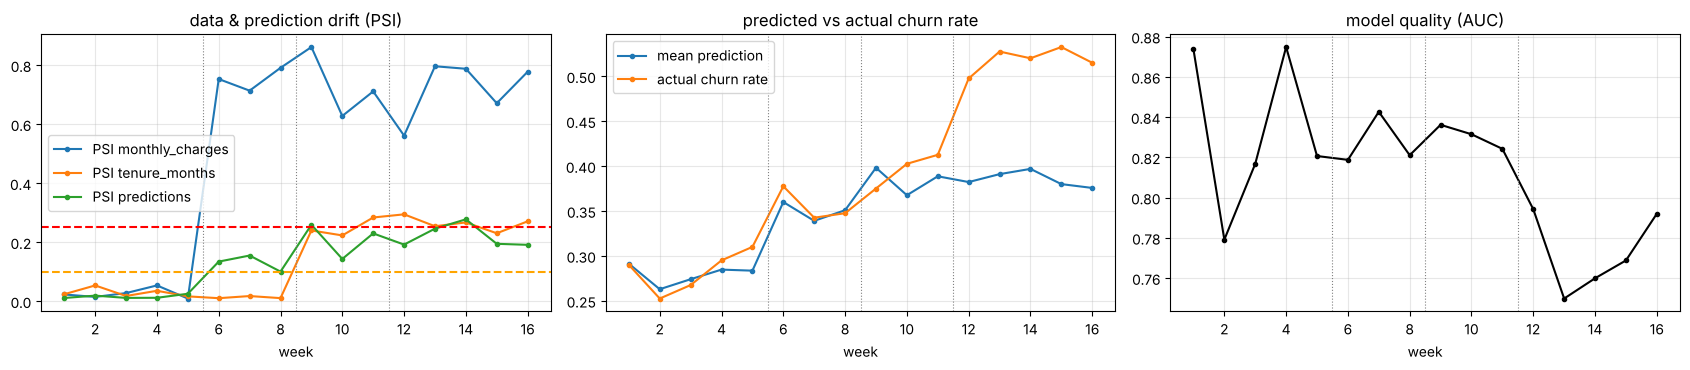

,PSI monthly_charges,PSI tenure_months,PSI predictions,mean prediction,actual churn rate,AUC (labels arrive later)
week,,,,,,
1,0.023,0.024,0.011,0.291,0.290,0.874
6,0.753,0.010,0.134,0.360,0.378,0.819
9,0.861,0.240,0.259,0.398,0.375,0.836
12,0.561,0.294,0.192,0.382,0.498,0.794
16,0.778,0.271,0.191,0.376,0.515,0.792


In [9]:
def production_week(week, seed):
    r = np.random.default_rng(seed)
    w = np.ones(len(X_live))                                                    # sampling weight per held-out customer
    if week >= 6: w *= np.exp(0.04 * (X_live["monthly_charges"].fillna(60).to_numpy() - 60))     # pricier customer mix
    if week >= 9: w *= np.where((X_live["tenure_months"] < 6).to_numpy(), 6.0, 1.0)              # flood of new sign-ups
    idx = r.choice(len(X_live), 400, replace=False, p=w / w.sum())
    Xw, yw = X_live.iloc[idx].copy(), y_live[idx].copy()                       # features AND outcomes stay consistent
    if week >= 12:                                                              # concept drift: pricey plans now churn more
        flip = (Xw["monthly_charges"] > 80).to_numpy() & (yw == 0) & (r.random(len(yw)) < 0.5)
        yw[flip] = 1
    return Xw, yw

weeks = range(1, 17); log = []
ref_scores = model_v1.predict_proba(X_train)[:, 1]
for w in weeks:
    Xw, yw = production_week(w, seed=w)
    p = model_v1.predict_proba(Xw)[:, 1]
    log.append({"week": w, "PSI monthly_charges": psi_numpy(X_train["monthly_charges"].to_numpy(), Xw["monthly_charges"].to_numpy()),
                "PSI tenure_months": psi_numpy(X_train["tenure_months"].to_numpy().astype(float), Xw["tenure_months"].to_numpy().astype(float)),
                "PSI predictions": psi_numpy(ref_scores, p), "mean prediction": p.mean(), "actual churn rate": yw.mean(),
                "AUC (labels arrive later)": roc_auc_score(yw, p)})
mon = pd.DataFrame(log).set_index("week")

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
mon[["PSI monthly_charges", "PSI tenure_months", "PSI predictions"]].plot(ax=axes[0], marker="o", ms=3)
axes[0].axhline(0.1, ls="--", c="orange"); axes[0].axhline(0.25, ls="--", c="red"); axes[0].set_title("data & prediction drift (PSI)")
mon[["mean prediction", "actual churn rate"]].plot(ax=axes[1], marker="o", ms=3); axes[1].set_title("predicted vs actual churn rate")
mon["AUC (labels arrive later)"].plot(ax=axes[2], marker="o", ms=3, c="k"); axes[2].set_title("model quality (AUC)")
for ax in axes:
    for wk, lbl in [(6, "price rise"), (9, "promo"), (12, "competitor")]: ax.axvline(wk - 0.5, c="gray", lw=0.8, ls=":")
plt.tight_layout(); plt.show()
mon.round(3).iloc[[0, 5, 8, 11, 15]]

Reading the dashboard:
- **Weeks 6 and 9:** data-drift alarms fire (PSI jumps), but the predicted churn rate **tracks** the actual rate as it rises, and AUC stays within its normal week-to-week noise (about ±0.04 with 400 customers a week). The model still describes these customers correctly; there are simply more of the risky ones. **Not every drift hurts.** The contact list will grow, though, and that's worth a human look (budget, call-centre capacity).
- **Week 12:** the input distributions **don't** change further, yet the actual churn rate jumps above the predicted rate and AUC drops. That's **concept drift** — invisible to input monitoring, caught only by comparing predictions with outcomes (or with proxy signals like cancellation-page visits). Monitor both.

## 6. Safe rollout: shadow, canary, A/B

You've trained model v2. Don't just swap it in:
1. **Offline evaluation** on recent data (beats v1? on all important segments?).
2. **Shadow mode:** v2 receives a copy of live traffic and makes predictions that are **logged but not used**. Compare with v1: disagreement rates, latency, errors — zero user risk.
3. **Canary:** route a small slice (1–5%) of real decisions to v2; watch errors, latency and business metrics; widen gradually.
4. **A/B test:** a randomised split with a pre-registered metric and sample size (notebook 13) to measure the real business impact.
5. **Rollback** instantly if anything degrades — keep v1 deployable.

Here, v2 is retrained on recent data that includes the new behaviour (from week 13–15 labels):

In [10]:
recent = [production_week(w, seed=100 + w) for w in range(13, 16)]
base = X_train.sample(1000, random_state=0); y_base = y_train[X_train.index.get_indexer(base.index)]   # some older data
X_recent = pd.concat([base] + [r_[0] for r_ in recent]); y_recent = np.concatenate([y_base] + [r_[1] for r_ in recent])
model_v2 = build_pipeline().fit(X_recent, y_recent)

# Shadow mode on week 16 traffic
Xw, yw = production_week(16, seed=999)
p1, p2 = model_v1.predict_proba(Xw)[:, 1], model_v2.predict_proba(Xw)[:, 1]
print(f"shadow comparison on week-16 traffic: decision disagreement {np.mean((p1 >= THRESHOLD) != (p2 >= THRESHOLD)):.1%}, "
      f"mean |Δp| {np.mean(np.abs(p1 - p2)):.3f}")
print(f"(labels arrive weeks later) AUC v1 {roc_auc_score(yw, p1):.3f} → v2 {roc_auc_score(yw, p2):.3f}; "
      f"calibration: predicted {p1.mean():.2f} / {p2.mean():.2f} vs actual {yw.mean():.2f}")

shadow comparison on week-16 traffic: decision disagreement 14.5%, mean |Δp| 0.124
(labels arrive weeks later) AUC v1 0.765 → v2 0.816; calibration: predicted 0.39 / 0.50 vs actual 0.58


In [11]:
# A/B test of the business outcome (simulated): two random groups of 4,000 customers, one scored by v1, one by v2
def simulate_campaign(model, n=4000, seed=0):
    r = np.random.default_rng(seed); Xc, yc = [], []
    for k in range(n // 400):
        a, b = production_week(16, seed=seed * 100 + k); Xc.append(a); yc.append(b)
    Xc, yc = pd.concat(Xc), np.concatenate(yc)
    contacted = model.predict_proba(Xc)[:, 1] >= THRESHOLD
    saved = contacted & (yc == 1) & (r.random(len(yc)) < 0.4)            # 40% of contacted would-be churners are saved
    return saved.sum(), contacted.sum()
s1, c1 = simulate_campaign(model_v1, seed=1); s2, c2 = simulate_campaign(model_v2, seed=2)
from statsmodels.stats.proportion import proportions_ztest
N = 4000
for name, (a, b, na, nb) in {"saved per CONTACTED customer (misleading)": (s2, s1, c2, c1),
                             "saved per customer in the group (the business metric)": (s2, s1, N, N)}.items():
    z, pval = proportions_ztest([a, b], [na, nb])
    print(f"{name:55s} v1 {b / nb:.1%} vs v2 {a / na:.1%}  (z = {z:.2f}, p = {pval:.4f})")
print(f"profit (notebook 09's numbers: $300 per saved customer, $30 per contact): v1 ${s1 * 300 - c1 * 30:,} vs v2 ${s2 * 300 - c2 * 30:,}")

saved per CONTACTED customer (misleading)               v1 26.7% vs v2 27.2%  (z = 0.43, p = 0.6656)
saved per customer in the group (the business metric)   v1 16.7% vs v2 20.2%  (z = 4.04, p = 0.0001)
profit (notebook 09's numbers: $300 per saved customer, $30 per contact): v1 $124,890 vs v2 $152,880


**Choose the A/B metric carefully.** v2 contacts *more* customers, so its success rate **per contact** looks no better. But that's the wrong denominator. What the business cares about is customers saved, or profit, **per customer in the group**, and on that metric v2 clearly wins. Decide the primary metric *before* the test, from the business goal (notebook 13: pre-registration).

In [12]:
# Decision: v2 saves significantly more customers and more money → promote it, keep v1 ready for rollback
registry_v2 = registry.register("churn", model_v2, X_recent, y_recent, {"week16_auc": round(roc_auc_score(yw, p2), 4)}, {"C": 1.0, "trained_on": "recent weeks 13-15"})
registry.set_stage("churn", registry_v2, "production")
print("production model now:", registry.load("churn")[1]["version"], "| v1 stage:", json.loads(Path("models/registry/churn/v1/meta.json").read_text())["stage"])

production model now: 2 | v1 stage: archived


## 7. When to retrain
- **On a schedule** (weekly/monthly) — simple and predictable; may be too slow for sudden shifts or wasteful when nothing changes.
- **On a trigger** — drift or performance alarms — responsive, but needs trustworthy monitoring.
- **Continual/online learning** — update incrementally on new data; powerful, but risky (feedback loops, poisoned data) and harder to audit.

Retraining needs **fresh labels**. For churn they arrive weeks later; for fraud, after chargebacks; for recommendations, instantly (clicks) but biased by what was shown (notebook 19). Beware **feedback loops**: customers v1 contacted and saved look like "non-churners" in the new data. Keep a small random **holdout** that receives no intervention so you can measure the true effect and train on unbiased labels.

## 8. Testing ML systems

Unit tests for code are necessary but not enough — test the **model's behaviour** too (inspired by "Beyond Accuracy: Behavioral Testing of NLP Models", Ribeiro et al. 2020, and Google's "ML Test Score"):

| Test | Example |
|---|---|
| **Data/feature unit tests** | `clean()` lower-cases regions; blank `total_charges` for new customers becomes 0 |
| **Invariance** | changing an irrelevant field (customer ID, region spelling) must not change the prediction |
| **Directional expectation** | more support calls → risk should not *decrease*; a two-year contract → lower risk than month-to-month |
| **Minimum performance** | AUC ≥ 0.78 overall *and* on each key segment, or the build fails |
| **Serving parity** | the API returns the same probability as the offline pipeline for the same record |

In [13]:
def test_clean_normalises_region():
    out = clean(raw.head(50).assign(region=["NORTH", "North ", "north"] * 16 + ["north", "north"]))
    assert set(out["region"]) == {"north"}

def test_invariance_to_region_spelling():
    a = client.post("/predict", json={**good, "region": "north"}).json()["churn_probability"]
    b = client.post("/predict", json={**good, "region": "  NORTH "}).json()["churn_probability"]
    assert abs(a - b) < 1e-9, (a, b)

def test_direction_support_calls():
    probs = [client.post("/predict", json={**good, "support_calls": k}).json()["churn_probability"] for k in range(0, 8)]
    assert all(b >= a - 1e-9 for a, b in zip(probs, probs[1:])), probs

def test_direction_contract():
    p = {c: client.post("/predict", json={**good, "contract": c}).json()["churn_probability"] for c in ["month-to-month", "one-year", "two-year"]}
    assert p["two-year"] < p["one-year"] < p["month-to-month"], p

def test_minimum_performance():
    m, _ = registry.load("churn")
    X_check, y_check = X_live.iloc[:1500], y_live[:1500]
    assert roc_auc_score(y_check, m.predict_proba(X_check)[:, 1]) >= 0.78
    for seg in ["month-to-month", "one-year", "two-year"]:
        mask = (X_check["contract"] == seg).to_numpy()
        assert roc_auc_score(y_check[mask], m.predict_proba(X_check[mask])[:, 1]) >= 0.65, seg

def test_serving_parity():
    api = client.post("/predict", json=good).json()["churn_probability"]
    offline = SERVING_MODEL.predict_proba(to_features([Customer(**good)]))[0, 1]
    assert abs(api - round(offline, 4)) < 1e-9

# A tiny test runner (in a real repo: put these in tests/ and run `pytest`)
for test in [test_clean_normalises_region, test_invariance_to_region_spelling, test_direction_support_calls,
             test_direction_contract, test_minimum_performance, test_serving_parity]:
    try: test(); print(f"✅ {test.__name__}")
    except AssertionError as e: print(f"❌ {test.__name__}: {e}")

✅ test_clean_normalises_region
✅ test_invariance_to_region_spelling
✅ test_direction_support_calls


✅ test_direction_contract
✅ test_minimum_performance
✅ test_serving_parity


Note `test_invariance_to_region_spelling` passes only *because* serving reuses `churn_utils.clean` — the same test would have caught the skew bug from Section 4.

## 9. Production readiness checklist

**Data**
- [ ] Features available at prediction time (no leakage); point-in-time correct joins
- [ ] One feature code path for training and serving (or a feature store); parity tests
- [ ] Input schemas + batch validation; alerts on failures

**Model**
- [ ] Beats a simple baseline offline, on every important segment (and fairness checks across groups)
- [ ] Calibrated, if probabilities drive decisions; threshold set from business costs
- [ ] Versioned in a registry with data fingerprint, code version, params, metrics, environment

**Serving**
- [ ] Batch vs online chosen deliberately; latency budget (p95/p99) measured
- [ ] Health checks, request logging (inputs, outputs, model version), graceful fallbacks (e.g. a rule) if the model fails
- [ ] Rollout via shadow → canary → A/B; one-click rollback

**Monitoring & maintenance**
- [ ] Data drift, prediction drift, and outcome/performance monitoring with sensible thresholds and owners
- [ ] Retraining process (schedule or trigger) with the same tests gating promotion
- [ ] Feedback-loop awareness: holdout groups, logging of what was shown/decided
- [ ] Documentation: a model card (purpose, data, metrics, limitations, owners)

## Key takeaways
- The model is a small part of an ML system; most failures are data and pipeline failures.
- Version everything; a registry ties each prediction back to its model, data and code.
- Validate inputs per request and per batch; reject or alert rather than predict on garbage.
- Training–serving skew is silent — share feature code, test parity, monitor feature distributions.
- Monitor data drift (PSI/KS), prediction drift and — once labels arrive — real performance; concept drift only shows up in outcomes.
- Roll out gradually (shadow → canary → A/B) with rollback ready; retrain on fresh, unbiased labels.
- Test model behaviour: invariance, directional expectations, minimum performance per segment.

## Exercises
1. Add a `/metrics` endpoint that returns the number of requests served and the mean predicted probability so far (hint: a module-level counter).
2. Extend `validate_batch` to check that the **mean predicted probability** of a batch is within ±50% of the training mean, and run it on weeks 1–16.
3. Implement a **canary router**: send 5% of requests (by a hash of the customer record) to v2 and 95% to v1, logging which model answered.
4. Write an invariance test showing that `avg_session_minutes` (a feature with ~no real effect) changes the prediction by less than 0.02 when doubled.

In [14]:
# Exercise 3 — solution
import hashlib
v1_model = joblib.load("models/registry/churn/v1/model.joblib"); v2_model = joblib.load("models/registry/churn/v2/model.joblib")
def canary_predict(record, share_v2=0.05):
    bucket = int(hashlib.md5(json.dumps(record, sort_keys=True).encode()).hexdigest(), 16) % 1000 / 1000   # stable per customer
    model, name = (v2_model, "v2") if bucket < share_v2 else (v1_model, "v1")
    return float(model.predict_proba(to_features([Customer(**record)]))[0, 1]), name
served = [canary_predict({**good, "tenure_months": int(t), "support_calls": int(s)})[1] for t, s in zip(rng.integers(0, 48, 600), rng.integers(0, 6, 600))]
print(f"share of requests served by v2: {served.count('v2') / len(served):.1%} (target 5%)")

share of requests served by v2: 5.7% (target 5%)


**🎉 That completes all 23 notebooks (00–22).** From a dot product to a monitored production system — and every step built from scratch first.

*Going deeper / interview prep:* `ML_System_Design_Notes.md` is the companion to this notebook: Part 0 (the 8-step framework), Part 2 (data validation, label leakage, point-in-time correctness, training–serving skew, labels, reproducibility & the registry), Part 3 (batch vs online, latency & queueing, dynamic batching, caching, reliability), Part 5 (rollout ladder, A/B testing, canaries, monitoring, retraining, thresholds & calibration, feedback loops), Part 6 (responsible & secure ML), Part 7 (ten worked case studies) and Part 8 (back-of-envelope estimation).